# `/predict` — comparaison des modèles et structure résiduelle

Premier des deux moteurs : estimer le rendement d'une parcelle à partir de ses conditions.

Ce notebook répond à deux questions, dans cet ordre :

1. **Reste-t-il quelque chose à apprendre ?** Avant de comparer des modèles, on teste si le
   résidu d'une régression linéaire contient encore de la structure. Sans ce repère, un R² de
   0,91 ne dit pas si le travail est fini ou s'il reste de la marge.
2. **Quelles variables garder ?** C'est ici que se tranchent les décisions différées par
   l'analyse exploratoire : durée de cycle, variables nominales, colonnes d'enrichissement.

Chaque évaluation est journalisée dans MLflow, avec son protocole et son jeu de variables.

# Imports

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor

sys.path.insert(0, str(Path.cwd().parent))

from src import config, tracking, utils
from src.models import evaluation, features, predict_model, protocole

utils.style()
np.random.seed(config.SEED)
tracking.configure(tracking.EXPERIENCE_PREDICT)

2026/10/09 15:58:55 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/09 15:58:55 INFO mlflow.store.db.utils: Updating database tables


2026/10/09 15:58:57 INFO mlflow.tracking.fluent: Experiment with name 'agritech-predict' does not exist. Creating a new experiment.


# Données et protocole

In [2]:
df = predict_model.charge()
print(f"{df.shape[0]:,} lignes x {df.shape[1]} colonnes")

# Booleans become 0/1 once and for all.
for colonne in df.columns:
    if df[colonne].dtype == bool:
        df[colonne] = df[colonne].astype(float)

X_app, X_test, y_app, y_test = protocole.decoupage_aleatoire(
    df, features.PREDICT_JEUX["toutes"], features.CIBLE_PREDICT
)
cv = protocole.cv_aleatoire()
print(f"apprentissage : {len(X_app):,} lignes")
print(f"test          : {len(X_test):,} lignes, réservé à l'évaluation finale")
print(cv)

999,769 lignes x 18 colonnes


apprentissage : 799,815 lignes
test          : 199,954 lignes, réservé à l'évaluation finale
KFold(n_splits=5, random_state=42, shuffle=True)


**Protocole, fixé une fois pour toutes :**

- découpage 80/20 figé par la graine 42 : le jeu de test est **le même pour tous les
  modèles** et ne sert à aucun choix ;
- validation croisée `KFold` à 5 plis sur le seul jeu d'apprentissage, mêmes plis pour
  tous — c'est ce qui autorise une comparaison appariée ;
- le préprocessing est **dans** le pipeline, donc réappris sur chaque pli : pas de fuite.

Le jeu simulé n'a ni année ni ordre : un découpage aléatoire y est légitime. Ce ne sera pas
le cas pour `/recommend` (notebook 09).

# 1. Reste-t-il quelque chose à apprendre ?

L'analyse exploratoire a montré que le rendement dépend de quatre variables, de façon
presque linéaire, et que les effets s'additionnent. Si c'est le cas, le résidu d'un modèle
linéaire ne contient plus que du bruit.

**Un piège à éviter.** On pourrait calculer un « plafond » `1 − σ²/Var(y)` à partir de
l'écart-type σ de ce résidu, et constater que le modèle linéaire l'atteint. Ce serait
circulaire : σ étant le résidu du modèle linéaire, cette quantité **est** son R², par
construction. Elle ne prouve rien.

**Le test qui prouve quelque chose** : entraîner un modèle souple, un gradient boosting
libre de modéliser interactions et non-linéarités, à **prédire le résidu** à partir de
**toutes** les variables disponibles, y compris celles que l'on compte écarter. Si son R²
hors échantillon est nul, aucune variable ne porte plus d'information exploitable : ce qui
reste est du bruit.

In [3]:
retenues = features.PREDICT_RETENUES
lineaire = predict_model.pipeline(LinearRegression(), retenues).fit(X_app[retenues], y_app)
predictions = lineaire.predict(X_test[retenues])

# The residual test sees every column of X_app: the 4 retained, but also crop, region,
# soil, weather, cycle length and the enrichment columns.
diagnostic = predict_model.diagnostic_residu(
    X_app, y_app - lineaire.predict(X_app[retenues]), X_test, y_test - predictions)
print(f"variables offertes au test : {X_app.shape[1]}")
print(diagnostic)
print(f"R² du modèle linéaire, hors échantillon = {evaluation.metriques(y_test, predictions)['test_r2']:.5f}")

variables offertes au test : 16
residu : sigma = 0.49927 t/ha | asymetrie +0.0076 | kurtosis -0.0143 | KS D = 0.00146
structure residuelle : R2 hors echantillon d'un boosting sur le residu = -0.00032
R² du modèle linéaire, hors échantillon = 0.91323


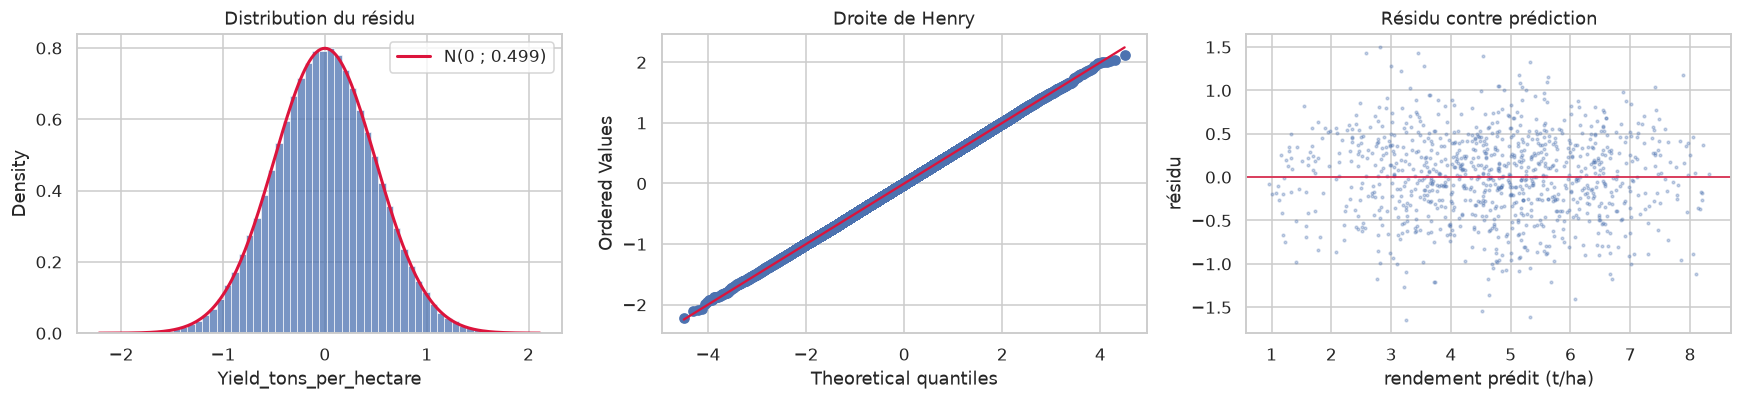

In [4]:
# Is the residual really Gaussian noise?
residu = y_test - predictions

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
sns.histplot(residu, bins=60, ax=axes[0], color="#4C72B0", stat="density")
abscisses = np.linspace(residu.min(), residu.max(), 200)
axes[0].plot(abscisses, (1 / (diagnostic.sigma * np.sqrt(2 * np.pi)))
             * np.exp(-0.5 * ((abscisses - residu.mean()) / diagnostic.sigma) ** 2),
             "crimson", lw=2, label=f"N(0 ; {diagnostic.sigma:.3f})")
axes[0].set_title("Distribution du résidu")
axes[0].legend()

from scipy import stats
stats.probplot(residu, dist="norm", plot=axes[1])
axes[1].set_title("Droite de Henry")
axes[1].get_lines()[1].set_color("crimson")

axes[2].scatter(predictions[::200], residu.to_numpy()[::200], s=3, alpha=0.3)
axes[2].axhline(0, c="crimson", lw=1)
axes[2].set_xlabel("rendement prédit (t/ha)")
axes[2].set_ylabel("résidu")
axes[2].set_title("Résidu contre prédiction")
utils.enregistre("07_residu_gaussien")
plt.show()

**Observations — il ne reste rien à apprendre, et c'est le résultat du notebook :**

- **Le boosting ne prédit rien du résidu** : son R² hors échantillon est nul (à quelques
  dix-millièmes près, et même légèrement négatif). Aucune variable, ni retenue ni écartée,
  aucune interaction, aucune non-linéarité ne porte d'information que le modèle linéaire
  aurait manquée.
- Le résidu a de plus la forme d'un **bruit gaussien** : asymétrie et kurtosis quasi nuls,
  droite de Henry rectiligne, variance constante sur toute la plage des prédictions. Seule,
  cette forme ne prouverait rien — un résidu gaussien peut encore dépendre des variables —
  c'est pourquoi le test précédent vient en premier.
- Son écart-type vaut **σ ≈ 0,499 t/ha** : c'est l'erreur typique que **tout** modèle
  commettra sur ces données, et le R² de 0,913 est donc le maximum atteignable avec elles.

> **Aucun modèle, aucun réglage ne peut faire mieux avec ces variables.** Le notebook 08 le
> vérifie encore par une campagne d'optimisation.

In [5]:
# Do the coefficients recover the process that generated the data?
table = predict_model.coefficients(lineaire, retenues)
table["effet sur la plage"] = [
    coef * (X_app[nom].max() - X_app[nom].min()) if nom in X_app else np.nan
    for nom, coef in zip(table["variable"], table["coefficient"])
]
table.round(5)

,variable,coefficient,effet sur la plage
0,Rainfall_mm,0.00499,4.49399
1,Temperature_Celsius,0.01990,0.49746
2,Fertilizer_Used,1.50104,1.50104
3,Irrigation_Used,1.19922,1.19922
4,(constante),0.00677,NaN


**Observations :** les coefficients ne sont pas seulement prédictifs, ils sont
**interprétables comme le générateur du jeu de données** :

| Variable | Coefficient | Lecture métier |
|---|---|---|
| `Rainfall_mm` | ≈ 0,005 /mm | +4,5 t/ha sur toute la plage de pluie |
| `Temperature_Celsius` | ≈ 0,020 /°C | +0,50 t/ha sur toute la plage |
| `Fertilizer_Used` | ≈ **1,50** | l'effet mesuré dans l'EDA, retrouvé exactement |
| `Irrigation_Used` | ≈ **1,20** | idem |
| constante | ≈ 0,00 | cohérent avec une somme d'effets sans terme de base |

C'est le même chiffrage que l'analyse exploratoire, obtenu par une voie indépendante. Un
contrôle automatique (`predict_model.controle_generateur`) fait échouer l'entraînement si
ces coefficients s'écartent de plus de 2 %.

# 2. Comparaison des modèles

Six familles, protocole identique. L'objectif n'est pas de trouver mieux — le test sur le
résidu l'exclut — mais de le **vérifier** modèle par modèle.

La recherche porte sur un sous-échantillon de 200 000 lignes : la machine ne dispose que de
4 Go libres, et une forêt sur un million de lignes les sature. Le R² est identique à la
cinquième décimale (vérifié ci-dessous), et le modèle retenu sera réajusté sur tout le jeu.

In [6]:
ECHANTILLON = 200_000
app = X_app.sample(ECHANTILLON, random_state=config.SEED)
y_ech = y_app.loc[app.index]

# Does the subsample change the measurement?
for n in (5_000, 50_000, ECHANTILLON, len(X_app)):
    sous = X_app.sample(n, random_state=config.SEED)[retenues]
    m = predict_model.pipeline(LinearRegression(), retenues).fit(sous, y_app.loc[sous.index])
    print(f"  {n:>7,} lignes  R² test = {m.score(X_test[retenues], y_test):.5f}")

    5,000 lignes  R² test = 0.91319
   50,000 lignes  R² test = 0.91322
  200,000 lignes  R² test = 0.91323


  799,815 lignes  R² test = 0.91323


In [7]:
MODELES = {
    "DummyRegressor": DummyRegressor(),
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0, random_state=None),
    "DecisionTree": DecisionTreeRegressor(min_samples_leaf=100, random_state=config.SEED),
    "RandomForest": RandomForestRegressor(
        n_estimators=100, min_samples_leaf=100, random_state=config.SEED, n_jobs=4),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=config.SEED),
}

plis_modeles = {}
for nom, modele in MODELES.items():
    plis = evaluation.validation_par_pli(
        predict_model.pipeline(modele, retenues), app[retenues], y_ech, cv)
    plis_modeles[nom] = plis
    metriques = evaluation.resume(plis)
    tracking.journalise(
        nom, {"modele": nom, "feature_set": "retenues", "protocole": "kfold5",
              "n_lignes": len(app)},
        metriques, etape="reference",
        note=f"Comparaison des familles sur les 4 variables retenues. {evaluation.ligne_lisible(metriques)}")
    print(f"  {nom:22} {evaluation.ligne_lisible(metriques)}")

  DummyRegressor         RMSE 1.6942 ± 0.0064 t/ha | MAE 1.3866 t/ha | R² -0.0000


  LinearRegression       RMSE 0.4996 ± 0.0019 t/ha | MAE 0.3986 t/ha | R² 0.9131


  Ridge                  RMSE 0.4996 ± 0.0019 t/ha | MAE 0.3986 t/ha | R² 0.9131


  DecisionTree           RMSE 0.5065 ± 0.0020 t/ha | MAE 0.4042 t/ha | R² 0.9106


  RandomForest           RMSE 0.5016 ± 0.0019 t/ha | MAE 0.4003 t/ha | R² 0.9123


  HistGradientBoosting   RMSE 0.5007 ± 0.0018 t/ha | MAE 0.3995 t/ha | R² 0.9126


In [8]:
evaluation.compare_appariee(plis_modeles, reference="LinearRegression").round(5)

,RMSE,MAE,R2,ecart a la reference,plis ameliores
DummyRegressor,1.69423,1.38659,-0.00002,1.19467,0/5
LinearRegression,0.49956,0.39859,0.91305,0.00000,0/5
Ridge,0.49956,0.39859,0.91305,0.00000,3/5
DecisionTree,0.50647,0.40420,0.91063,0.00691,0/5
RandomForest,0.50158,0.40026,0.91235,0.00202,0/5
HistGradientBoosting,0.50073,0.39954,0.91265,0.00117,0/5


**Observations :**

- Le `DummyRegressor` donne une RMSE égale à l'écart-type du rendement : la régression
  linéaire la réduit d'environ **70 %**.
- **Aucun modèle ne bat la régression linéaire**, et la colonne « plis améliorés » le dit
  plus clairement qu'une moyenne : les écarts ne tiennent sur aucun pli.
- Les meilleurs boostings s'en approchent à moins d'un millième de t/ha, pour un
  entraînement bien plus long. L'arbre seul est le plus loin : il approxime par paliers une
  relation qui est droite.

C'est cohérent avec l'EDA : les relations sont presque linéaires et les effets s'additionnent.
Les modèles souples n'ont pas de structure supplémentaire à apprendre.

# 3. Quelles variables garder ?

Les décisions différées par l'analyse exploratoire se tranchent ici, en mesurant l'apport
de chaque groupe de variables à protocole constant.

In [9]:
plis_jeux = {}
for nom, variables in features.PREDICT_JEUX.items():
    plis = evaluation.validation_par_pli(
        predict_model.pipeline(LinearRegression(), variables), app[variables], y_ech, cv)
    plis_jeux[nom] = plis
    metriques = evaluation.resume(plis)
    tracking.journalise(
        f"LinearRegression — {nom}",
        {"modele": "LinearRegression", "feature_set": nom, "protocole": "kfold5",
         "n_variables": len(variables)},
        metriques, etape="ablation",
        note=f"Ablation : {len(variables)} variables. {evaluation.ligne_lisible(metriques)}")
    print(f"  {nom:26} {len(variables):2d} variables  {evaluation.ligne_lisible(metriques)}")

  retenues                    4 variables  RMSE 0.4996 ± 0.0019 t/ha | MAE 0.3986 t/ha | R² 0.9131


  retenues_duree              5 variables  RMSE 0.4996 ± 0.0019 t/ha | MAE 0.3986 t/ha | R² 0.9131


  retenues_categorielles      8 variables  RMSE 0.4996 ± 0.0019 t/ha | MAE 0.3986 t/ha | R² 0.9130


  retenues_enrichissement    11 variables  RMSE 0.4996 ± 0.0019 t/ha | MAE 0.3986 t/ha | R² 0.9130


  toutes                     16 variables  RMSE 0.4996 ± 0.0019 t/ha | MAE 0.3986 t/ha | R² 0.9130


In [10]:
evaluation.compare_appariee(plis_jeux, reference="retenues").round(6)

,RMSE,MAE,R2,ecart a la reference,plis ameliores
retenues,0.499561,0.398590,0.913052,0.000000,0/5
retenues_duree,0.499567,0.398593,0.913050,0.000006,1/5
retenues_categorielles,0.499584,0.398616,0.913044,0.000024,0/5
retenues_enrichissement,0.499569,0.398598,0.913049,0.000008,2/5
toutes,0.499594,0.398620,0.913041,0.000033,0/5


**Observations — les quatre décisions, tranchées :**

| Ajout testé | Apport sur la RMSE | Décision |
|---|---|---|
| `Days_to_Harvest` | nul | **écartée** du modèle |
| Les 4 variables nominales, dont `Crop` | nul | **écartées** |
| Les 6 colonnes d'enrichissement + l'écart à la niche | nul | **écartées** |
| Tout | nul | — |

Les écarts se jouent à la sixième décimale, bien en dessous de la variation d'un pli à
l'autre. **Les quatre variables retenues portent tout le signal.**

> **Conséquence inconfortable, à écrire.** Les colonnes d'enrichissement issues du jeu FAO
> n'apportent **rien** à ce modèle. C'était annoncé à l'étape 1 : la cible est le rendement
> simulé, qui ne dépend pas de la culture, et `crop_ref_yield_t_ha` est colinéaire à `Crop`.
> La corrélation entre les deux avait été mesurée à **−0,0007**. Le dataset consolidé reste
> le livrable demandé et la source de ce service, mais **sa moitié enrichie est inerte**.
> `/recommend` ne s'appuiera pas sur elle : il aura son propre modèle (notebook 09).

In [11]:
# The absence of crop effect, seen differently: the same plot replayed with the 6 crops.
parcelle = X_test[features.PREDICT_JEUX["toutes"]].iloc[[0]]
avec_crop = features.PREDICT_RETENUES + ["Crop"]
modele_crop = predict_model.pipeline(LinearRegression(), avec_crop).fit(
    app[avec_crop], y_ech)

essais = pd.concat([parcelle.assign(Crop=culture) for culture in sorted(df["Crop"].unique())])
estimations = pd.Series(modele_crop.predict(essais[avec_crop]),
                        index=sorted(df["Crop"].unique()), name="rendement estimé (t/ha)")
print(estimations.round(4).to_string())
print(f"\nécart entre la meilleure et la moins bonne culture : "
      f"{estimations.max() - estimations.min():.4f} t/ha")
print(f"erreur typique du modèle                          : {diagnostic.sigma:.4f} t/ha")

Barley     4.1024
Cotton     4.1014
Maize      4.1007
Rice       4.1047
Soybean    4.1050
Wheat      4.1015

écart entre la meilleure et la moins bonne culture : 0.0043 t/ha
erreur typique du modèle                          : 0.4993 t/ha


**Observations :** à conditions identiques, changer la culture déplace l'estimation de
quelques millièmes de t/ha, pour une erreur typique de 0,50 t/ha — soit **cent fois moins
que le bruit**. Demander la culture pour estimer un rendement n'a pas de sens dans ce jeu.

**Choix retenu pour l'interface :** la culture sera tout de même demandée, parce que le
sujet le prévoit et que l'utilisateur raisonne par culture, mais **la réponse du service
indiquera que l'estimation n'en dépend pas**. Masquer le champ serait plus cohérent avec le
modèle ; l'afficher en le qualifiant est plus honnête envers l'utilisateur, qui comprendrait
mal son absence.

# Conclusion

## Il ne reste rien à apprendre
Un gradient boosting entraîné à prédire le résidu du modèle linéaire, à partir de **toutes**
les variables, obtient un R² hors échantillon **nul**. Le résidu est un bruit gaussien
d'écart-type 0,499 t/ha : le R² de **0,913** est le maximum atteignable avec ces données.
(Le « plafond » `1 − σ²/Var(y)` n'est pas utilisé comme preuve : calculé sur le résidu
linéaire, il est égal au R² linéaire par construction.)

## Le générateur, retrouvé
Les coefficients reconstituent le processus qui a engendré les données :

```
rendement = 0,005·pluie + 0,020·température + 1,50·engrais + 1,20·irrigation + N(0 ; 0,50)
```

Ce sont les effets **du jeu simulé**. Le notebook 05 a montré que les données FAO réelles n'en
confirment que la direction pour les intrants, et pas le rôle dominant de la pluie.

## Les variables clés
`Rainfall_mm`, `Fertilizer_Used`, `Irrigation_Used`, `Temperature_Celsius`. Les cinq autres
groupes testés n'apportent rien de mesurable.

## Les décisions différées, tranchées
- `Days_to_Harvest` : **écartée**.
- Variables nominales, `Crop` comprise : **écartées** du modèle.
- Colonnes d'enrichissement : **écartées** — elles ne peuvent rien prédire de cette cible.
- **Pesticides** : le sujet les cite comme exemple de condition de parcelle, mais le jeu
  simulé n'en contient pas. `/predict` ne peut donc pas en tenir compte, et l'interface ne
  doit pas les demander pour ce service.

## Ce qui reste à faire
Le notebook 08 mène la campagne d'optimisation : non pour espérer dépasser ce maximum, mais
pour le vérifier expérimentalement et en garder la trace dans MLflow.